In [5]:
import matplotlib.pyplot as plt

In [18]:
import pandas as pd

df = pd.read_excel("bitcoin market features table 10.xlxs.xlsx")

In [19]:
df[["trade_date", "close_price"]].head(10)

,trade_date,close_price
0,2015-10-13,249.507996
1,2016-05-31,531.385986
2,2020-06-22,9648.717773
3,2019-12-08,7564.345215
4,2020-02-11,10208.236330
5,2019-04-21,5314.531250
6,2022-08-14,24319.333980
7,2023-02-08,22939.398440
8,2024-06-02,67751.601560
9,2025-02-09,96500.093750


In [21]:
df["trade_date"] = pd.to_datetime(df["trade_date"])

In [22]:
df = df.sort_values("trade_date")

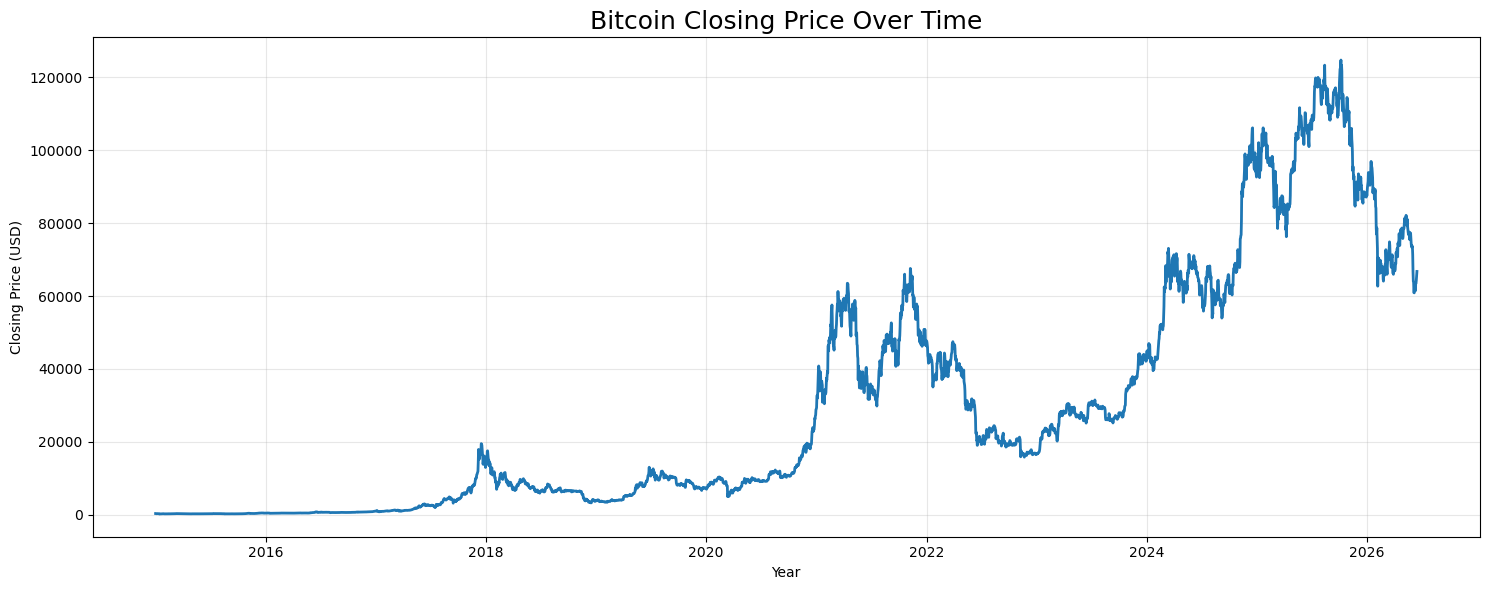

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))

plt.plot(df["trade_date"], df["close_price"], linewidth=2)

plt.title("Bitcoin Closing Price Over Time", fontsize=18)

plt.xlabel("Year")

plt.ylabel("Closing Price (USD)")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

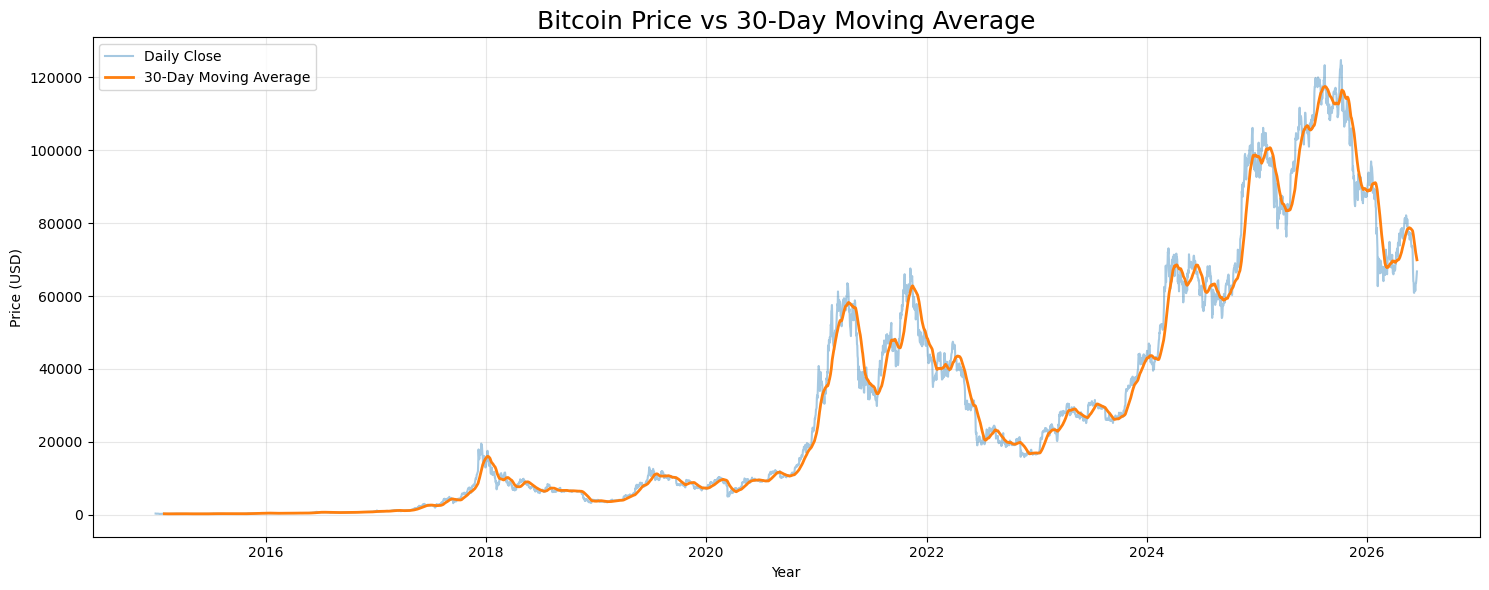

In [25]:
df["MA30"] = df["close_price"].rolling(window=30).mean()

plt.figure(figsize=(15,6))

plt.plot(df["trade_date"], df["close_price"], alpha=0.4, label="Daily Close")

plt.plot(df["trade_date"], df["MA30"], linewidth=2, label="30-Day Moving Average")

plt.title("Bitcoin Price vs 30-Day Moving Average", fontsize=18)

plt.xlabel("Year")

plt.ylabel("Price (USD)")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

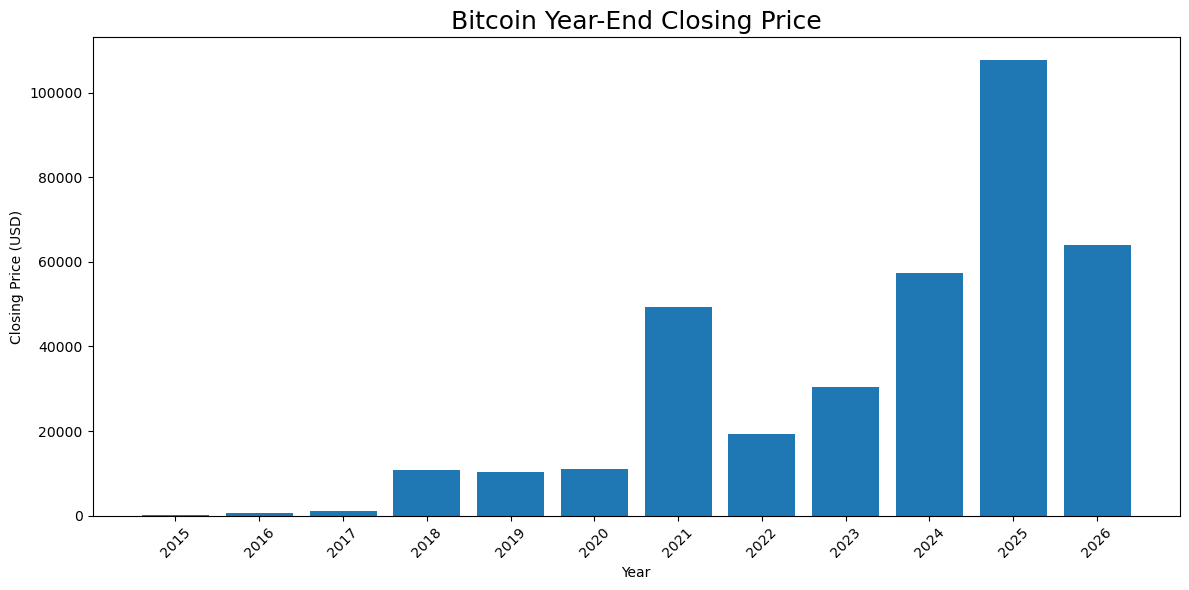

In [15]:
yearly_price = (
    df.groupby(df["trade_date"].dt.year)["close_price"]
      .last()
)

plt.figure(figsize=(12,6))

plt.bar(yearly_price.index.astype(str), yearly_price.values)

plt.title("Bitcoin Year-End Closing Price", fontsize=18)

plt.xlabel("Year")

plt.ylabel("Closing Price (USD)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()